In [34]:
import pandas as pd 
import matplotlib.pyplot as plt 
from sklearn.preprocessing import StandardScaler
import numpy as np

In [35]:
df = pd.read_csv("thyroid_dataset.csv")

In [36]:
df.head()

,Age,Sex,on_thyroxine,query_on_thyroxine,on_antithyroid_medication,sick,pregnant,thyroid_surgery,I131_treatment,query_hypothyroid,query_hyperthyroid,lithium,goitre,tumor,hypopituitary,psych,TSH,T3_measured,TT4_measured,T4U_measured,FTI_measured,Outlier_label
0,0.45,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,61.0,6.0,23.0,87.0,26.0,o
1,0.61,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,29.0,15.0,61.0,96.0,64.0,o
2,0.16,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,29.0,19.0,58.0,103.0,56.0,o
3,0.85,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,114.0,3.0,24.0,61.0,39.0,o
4,0.75,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,49.0,3.0,5.0,116.0,4.0,o


In [37]:
df.shape 

(6916, 22)

In [38]:
x = df.drop("Outlier_label" , axis=1)
y = df["Outlier_label"]

In [39]:
x.head()

,Age,Sex,on_thyroxine,query_on_thyroxine,on_antithyroid_medication,sick,pregnant,thyroid_surgery,I131_treatment,query_hypothyroid,query_hyperthyroid,lithium,goitre,tumor,hypopituitary,psych,TSH,T3_measured,TT4_measured,T4U_measured,FTI_measured
0,0.45,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,61.0,6.0,23.0,87.0,26.0
1,0.61,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,29.0,15.0,61.0,96.0,64.0
2,0.16,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,29.0,19.0,58.0,103.0,56.0
3,0.85,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,114.0,3.0,24.0,61.0,39.0
4,0.75,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,49.0,3.0,5.0,116.0,4.0


In [40]:
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)

In [41]:
from sklearn.ensemble import IsolationForest

clf = IsolationForest(n_estimators=200 , contamination='auto' , random_state=42)


In [42]:
labels = clf.fit_predict(x_scaled)

In [43]:
# Visualize 

from sklearn.decomposition import PCA

pca = PCA(n_components=2)
x_pca = pca.fit_transform(x_scaled)

Text(0, 0.5, 'PC2')

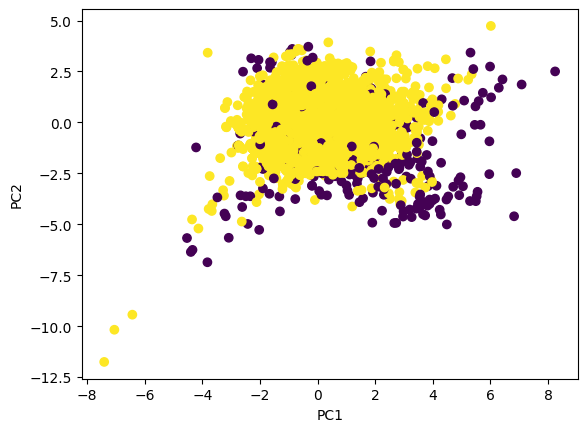

In [44]:
plt.Figure(figsize=(8,6))

plt.scatter(x_pca[:,0] , x_pca[:,1] , c=labels)
plt.xlabel("PC1")
plt.ylabel("PC2")

In [45]:
n_outliers = np.sum(labels== -1)
n_normal = np.sum(labels == 1)   

print ("outliers :" , n_outliers)
print ("normals :" , n_normal)

outliers : 270
normals : 6646


LOF (local outlier factor )

Text(0, 0.5, 'PC2')

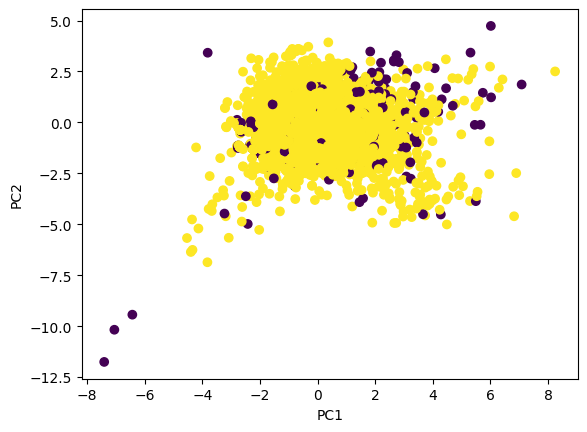

In [46]:
from sklearn.neighbors import LocalOutlierFactor

neighbor  = LocalOutlierFactor(contamination=0.036)
labells = neighbor.fit_predict(x_scaled)

plt.Figure(figsize=(8,6))

plt.scatter(x_pca[:,0] , x_pca[:,1] , c=labells)
plt.xlabel("PC1")
plt.ylabel("PC2")



In [47]:
n_outliers = np.sum(labells== -1)
n_normal = np.sum(labells == 1)   

print ("outliers :" , n_outliers)
print ("normals :" , n_normal)

outliers : 249
normals : 6667
